# Week 5 · 04 micrograd: build an autograd engine

`loss.backward()` in PyTorch does for **any** formula what you did by hand in `03`. Here you build a small version of it for single numbers, about 60 lines: a `Value` class that remembers how each number was computed, and a `backward()` that runs the chain rule through the whole computation. It's also the most Python-heavy notebook so far, on purpose: special methods like `__add__`, functions stored inside objects (closures), sets and recursion. The design follows Andrej Karpathy's teaching library *micrograd*; the examples and exercises are new.

**How to use this notebook**
- Run cells one at a time with **Shift + Enter**.
- Before running an example, **guess what it prints**. The real result is written after `# →` in the comments, so you can check yourself.
- **Your turn** cells are for you. Open **Show one answer** only after a real attempt.
- If things get weird, click **Restart** at the top and run from the top again.

## Words you'll see
- **special method (dunder)**: a method with two underscores on each side, such as `__add__`. Python calls it for you: `a + b` runs `a.__add__(b)`.
- **closure**: a function defined inside another function. It remembers the variables around it, even after the outer function has returned.
- **node**: one `Value` in the computation graph: an input, a weight, or an intermediate result.
- **leaf**: a node that wasn't computed from other nodes: an input or a parameter.
- **topological order**: a list of the nodes in which every node comes after all the nodes it was computed from.

**Run this cell first.** It loads NumPy, the picture helpers (`figures.py` in this folder) and the exercise checker.

In [1]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
from figures import *
import checks; checks.load(globals(), "04")      # defines check(n)

## M. The map: what's in this notebook and why

🖼 **Picture.** The plan: the Python you need, then the `Value` class and its `backward`, then a network made of `Value`s, trained and compared with PyTorch.

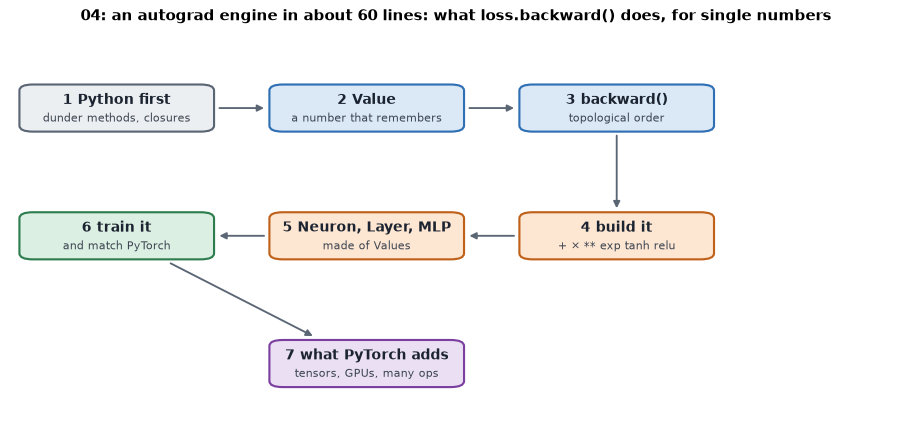

In [2]:
fig_micro_map()

| Section | What | Why it's here |
|---|---|---|
| 0 | recap, and the M-step from memory | the chain-rule facts the engine is built on; spaced practice of `01` |
| E | the finished engine's answer, from PyTorch | start from the end: the numbers your engine must reproduce |
| 1 | the Python you need | special methods, closures, sets and recursion, each on a tiny example first |
| 2 | `Value`: a number that remembers | the design: what each object stores and each operation's local rule |
| 3 | `backward()` | the algorithm card: topological order, then the rules in reverse |
| 4 | build it | exercises 2–5: your engine, operation by operation |
| 5 | `Neuron`, `Layer`, `MLP` | a network made of `Value`s (exercise 6) |
| 6 | train it, and match PyTorch | the engine trains a network, and PyTorch gives the same gradients |
| 7 | what PyTorch adds | the same idea, for whole arrays and on GPUs |

## 0. Recap first · 10 min, closed book

**Quick check:** In a computation graph, what does a **multiply** box send back to each input? An **add** box?

<details><summary>Answer</summary>

Multiply: the upstream gradient times the **other** input. Add: the upstream gradient, unchanged, to both. [03 §2 ↗](03_backprop.ipynb)

</details>

**Quick check:** A value feeds two boxes. How do the gradients coming back from them combine?

<details><summary>Answer</summary>

They **add up** (the multivariable chain rule). [03 §2 ↗](03_backprop.ipynb)

</details>

**Quick check:** $\frac{d}{dz}\tanh(z) = $ ?

<details><summary>Answer</summary>

$1 - \tanh^2(z)$, which can be computed from the output $\tanh(z)$ alone.

</details>

**Quick check:** In which order does backpropagation visit the boxes, and why?

<details><summary>Answer</summary>

From the loss backwards: a box's upstream gradient must be complete (all its users processed) before it can pass it on. [03 §5 ↗](03_backprop.ipynb)

</details>

**Quick check:** Why must a numerical-gradient function put each entry of `theta` back after nudging it?

<details><summary>Answer</summary>

Otherwise it changes the caller's array (an in-place change), the trap from `00` A2. [03 §6 ↗](03_backprop.ipynb)

</details>

**Exercise 1 · The M-step, from memory.** Return `(mu, var, pi)`, each **shape `(K,)`**: $N_k = \sum_i r_{ik}$, $\mu_k = \frac{1}{N_k}\sum_i r_{ik} x_i$, $\sigma_k^2 = \frac{1}{N_k}\sum_i r_{ik}(x_i - \mu_k)^2$ (new $\mu_k$), $\pi_k = N_k / n$. `x` `(n,)`, `R` `(n, K)`. No loops.

**Example**: what goes in, and what should come out:
```python
x = np.array([1, 2, 3, 6, 7, 8.0])
R = np.array([[0.867, 0.133], [0.755, 0.245], [0.593, 0.407],
              [0.133, 0.867], [0.068, 0.932], [0.033, 0.967]])     # (6, 2), rows sum to 1
m_step(x, R)[0]    # → [2.325 6.   ]   the means (01's 2.324, up to the rounding of R)
```

In [41]:
x = np.array([1, 2, 3, 6, 7, 8.0])
R = np.array([[0.867, 0.133], [0.755, 0.245], [0.593, 0.407],
              [0.133, 0.867], [0.068, 0.932], [0.033, 0.967]])
print(R.sum(axis=0))
mu = np.array([2,3])
print((((x[:,None] - mu)**2)*R)/mu)
print(R.shape)

[2.449 3.551]
[[0.4335     0.17733333]
 [0.         0.08166667]
 [0.2965     0.        ]
 [1.064      2.601     ]
 [0.85       4.97066667]
 [0.594      8.05833333]]
(6, 2)


In [44]:
def m_step(x, R): # x : (n,)
    Nk = R.sum(axis=0) #(K,)
    mu = (R*x[:,None]).sum(axis = 0)/Nk #(K,)
    var = (((x[:,None] - mu)**2)*R).sum(axis=0)/Nk #(n,K)
    pi = Nk/len(x)
    return mu, var, pi

In [45]:
check(1)

Exercise 1: PASS


## E. Start from the end: what the engine computes

A single neuron, $o = \tanh(x_1 w_1 + x_2 w_2 + b)$, with $x_1 = 1$, $x_2 = -2$, $w_1 = 0.5$, $w_2 = 0.25$, $b = 0.3$. An autograd engine does two things: the **forward** pass computes $o$, and `backward()` fills in $\partial o / \partial(\text{every input and weight})$. PyTorch's engine, on this neuron:

In [46]:
import torch
t = {k: torch.tensor(v, dtype=torch.float64, requires_grad=True) for k, v in dict(x1=1.0, w1=0.5, x2=-2.0, w2=0.25, b=0.3).items()}
o = torch.tanh(t["x1"] * t["w1"] + t["x2"] * t["w2"] + t["b"])
o.backward()                                         # fills .grad of every tensor that has requires_grad=True
print(round(o.item(), 4), {k: round(v.grad.item(), 4) for k, v in t.items()})
# → 0.2913 {'x1': 0.4576, 'w1': 0.9151, 'x2': 0.2288, 'w2': -1.8303, 'b': 0.9151}

0.2913 {'x1': 0.4576, 'w1': 0.9151, 'x2': 0.2288, 'w2': -1.8303, 'b': 0.9151}


🖼 **Picture.** The computation as a graph: every intermediate result is a box, every operation a circle. In black, each box's value; in red, $\partial o / \partial(\text{that value})$.

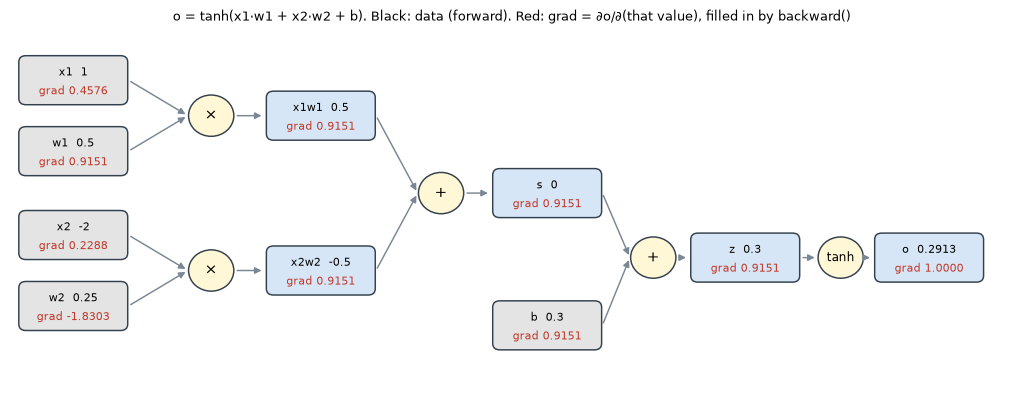

In [6]:
fig_value_graph()

Read one gradient: $\partial o / \partial w_2 = -1.8303$. Nudging $w_2$ up by $0.01$ would change $o$ by about $-0.018$. It's negative because $w_2$ multiplies $x_2 = -2$.

**By the end of this notebook, your own `Value` class prints exactly these numbers.** The rest answers: how does an object "remember" how it was computed, and in which order must the chain rule be applied so that every gradient is complete?

## 1. The Python you need

Three pieces of Python make the engine possible. Each one first on a tiny example.

**1a. Special methods: what `a + b` really calls**

When you write `a + b`, Python calls `a.__add__(b)`. If you define `__add__` in your class, `+` works on your objects. The full list we need:

| You write | Python calls | Note |
|---|---|---|
| `a + b` | `a.__add__(b)` |  |
| `a * b` | `a.__mul__(b)` |  |
| `a ** 2` | `a.__pow__(2)` |  |
| `-a` | `a.__neg__()` |  |
| `a - b` | `a.__sub__(b)` |  |
| `a / b` | `a.__truediv__(b)` |  |
| `2 + a` | first `int.__add__(2, a)`, which gives up; then `a.__radd__(2)` | r = "reflected": the number is on the left |
| `print(a)` | `a.__repr__()` | what the object looks like when printed |
| `model(x)` | `model.__call__(x)` | makes an object callable like a function (PyTorch modules work this way) |

In [49]:
class Num:
    def __init__(self, v):
        self.v = v
    def __add__(self, other):          # Num + Num
        return Num(self.v + other.v)
    def __repr__(self):
        return f"Num({self.v})"

print(Num(2) + Num(3))                 # → Num(5)
try:
    print(2 + Num(3))                  # int doesn't know Num, and Num has no __radd__
except TypeError as e:
    print("TypeError:", e)
# → TypeError: unsupported operand type(s) for +: 'int' and 'Num'

Num(5)
TypeError: unsupported operand type(s) for +: 'int' and 'Num'


**1b. Closures: a function that remembers its surroundings**

A function defined **inside** another function can use the outer function's variables, and it keeps them after the outer function has returned. And because functions are objects, you can store one in an attribute and call it later:

In [51]:
def make_adder(k):
    def add(x):
        return x + k           # k is remembered from the call make_adder(3)
    return add

add3 = make_adder(3)
print(add3(10))                # → 13

13


**What happens step by step:**

1. **`make_adder(3)` runs.** Inside it, `k = 3`.
2. **`add` is defined.** It uses `k`, which isn't one of its own parameters. Python sees this and attaches a reference to the outer `k` to the function. A function bundled with variables from its surroundings is a **closure**.
3. **`return add`.** This returns the function itself, not a call to it (there are no parentheses). `make_adder` is now finished, and normally its local `k` would disappear.
4. **But `k` survives**, because `add` still holds a reference to it. So `add3` is "a function that adds 3."
5. **`add3(10)`** runs `10 + k` with the remembered `k = 3`, which gives `13`.

In [50]:
class Box:
    pass
b = Box()
b.say = lambda: "hello"        # store a function in an attribute ...
print(b.say())                 # → hello      ... and call it later

hello


- `lambda: "hello"` makes a small function that takes no arguments and returns `"hello"`.
- In Python, a function is a value like a number or a list. You can put it in a variable, a list, or (here) **an attribute of an object**.
- `b.say` (no parentheses) is the function itself. `b.say()` calls it.

**Why both are taught together**

Combined, they give the autograd pattern: when an operation creates a new node, it builds a closure that remembers the operation's inputs and stores it on the output node so it can be called later:

```python
def __add__(self, other):
    out = Value(self.data + other.data)
    def _backward():                  # closure: remembers self, other, out
        self.grad  += out.grad
        other.grad += out.grad
    out._backward = _backward         # stored in an attribute
    return out
```

During backprop you just call `node._backward()` on each node in reverse order. Each node already "knows" which inputs to send its gradient to, because its closure captured them when the node was created.

The engine combines both: when `a * b` runs, it creates the result `out` **and** a small function `_backward` that remembers `a`, `b` and `out`. It stores that function in `out._backward`. Later, `backward()` calls it, and it knows exactly whose gradients to update.

**1c. Sets and recursion: listing a graph in order**

To apply the chain rule backwards, we need every node listed **after** the nodes it was made from (a topological order). A recursive visit does it: list everything a node was made from first, then the node. A `set` of visited nodes stops a node that is used twice from being listed twice. The neuron's graph, with names standing in for the nodes:

In [9]:
made_from = {"o": ["z"], "z": ["s", "b"], "s": ["x1w1", "x2w2"], "x1w1": ["x1", "w1"], "x2w2": ["x2", "w2"],
             "x1": [], "w1": [], "x2": [], "w2": [], "b": []}
order, visited = [], set()

def visit(name):
    if name in visited:            # already listed: a node used twice is listed once
        return
    visited.add(name)
    for child in made_from[name]:
        visit(child)               # first list everything it was made from ...
    order.append(name)             # ... then the node itself

visit("o")
print(order)   # → ['x1', 'w1', 'x1w1', 'x2', 'w2', 'x2w2', 's', 'b', 'z', 'o']

['x1', 'w1', 'x1w1', 'x2', 'w2', 'x2w2', 's', 'b', 'z', 'o']


🖼 **Picture.** The same order on the graph. Reading it **backwards** (from #10 to #1) visits every node after all the nodes that use it, which is exactly what backpropagation needs.

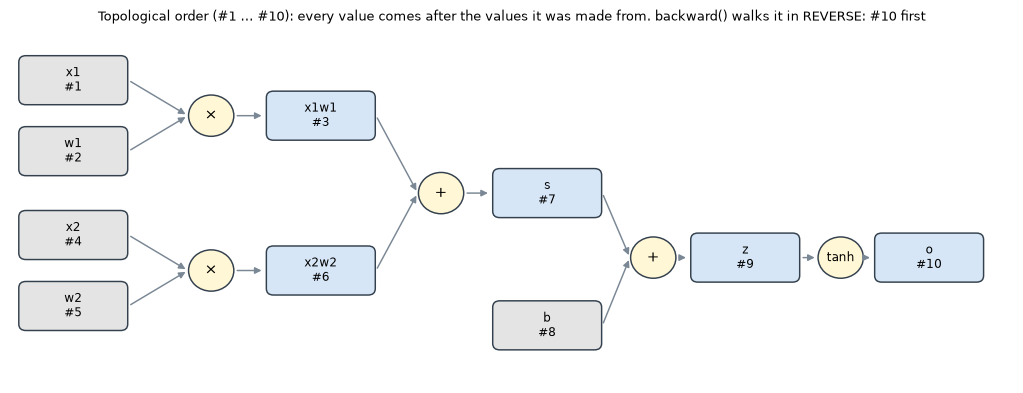

In [10]:
fig_value_graph('order')

## 2. `Value`: a number that remembers where it came from

**The design.** Every number in the computation becomes a `Value` object holding five things:

| Attribute | Holds | For $z = s + b$ in the neuron |
|---|---|---|
| `data` | the number | `0.3` |
| `grad` | $\partial(\text{output}) / \partial(\text{this value})$, 0 until `backward()` runs | `0.9151` after `backward()` |
| `_prev` | the set of `Value`s it was computed from | `{s, b}` |
| `_op` | the operation's name, for printing | `'+'` |
| `_backward` | a function that adds this node's contribution to its children's `grad` | adds `z.grad` to `s.grad` and to `b.grad` |

Each operation creates the result **and** its `_backward`. The local rules are the derivatives you know; the upstream gradient is `out.grad`:

| Operation | Forward: `out.data =` | `_backward` does |
|---|---|---|
| `a + b` | `a.data + b.data` | `a.grad += out.grad`; `b.grad += out.grad` |
| `a * b` | `a.data * b.data` | `a.grad += b.data * out.grad`; `b.grad += a.data * out.grad` |
| `a ** k` ($k$ a number) | `a.data ** k` | `a.grad += k * a.data ** (k - 1) * out.grad` |
| `a.exp()` | $e^{a}$ | `a.grad += out.data * out.grad` |
| `a.tanh()` | $\tanh(a)$ | `a.grad += (1 - out.data ** 2) * out.grad` |
| `a.relu()` | $\max(0, a)$ | `a.grad += (out.data > 0) * out.grad` |

**Why `+=` and never `=`.** A node can feed several operations (a fan-out), and its gradient is the **sum** of what comes back (`03` §2). With `=`, the last contribution would overwrite the others. Example: $f = a \cdot a$ with $a = 3$, so $f' = 2a = 6$. Here `self` and `other` are the same object `a`:

| Line of `__mul__`'s `_backward` | With `+=` | With `=` |
|---|---|---|
| `self.grad ... other.data * out.grad` | a.grad = 0 + 3 = 3 | a.grad = 3 |
| `other.grad ... self.data * out.grad` | a.grad = 3 + 3 = **6** ✓ | a.grad = 3 ✗ (overwritten) |

**Why `isinstance(other, Value)`** in `__add__`: so that `v + 2` works; the plain number 2 is wrapped into `Value(2)` first.

## 3. `backward()`: the algorithm card

**Goal.** For an output node `out` (usually the loss), fill `.grad` of every node in its graph with $\partial(\text{out}) / \partial(\text{node})$.

**Steps.**

- **Order**: build a topological order `topo` of all nodes reachable from `out` (the recursive visit of §1c, following `_prev`).
- **Seed**: `out.grad = 1.0`, since $\partial(\text{out}) / \partial(\text{out}) = 1$.
- **Propagate**: for each node `v` in `reversed(topo)`, call `v._backward()`.

**Why it works.** When `v._backward()` runs, `v.grad` must already be complete, i.e. every node that **uses** `v` must have added its contribution. In a topological order every user of `v` comes after `v`, so in the reversed order it comes **before** `v`: all contributions have arrived. Leaves (inputs and weights) have nothing to pass on; their `_backward` does nothing.

**Caveats.** (1) Gradients **accumulate**: calling `backward()` twice adds everything twice. Before each training step, set every parameter's `grad` back to 0. PyTorch has the same behaviour, which is why every training loop calls `optimizer.zero_grad()` (`06` §5). (2) The recursion goes as deep as the graph: Python stops at about 1000 nested calls, so very deep graphs need a loop instead of recursion. (3) The graph is rebuilt on every forward pass (PyTorch calls this "define-by-run"), so `if`s and loops in the forward code just work.

**Cost.** Each node is listed once and its `_backward` runs once: time proportional to the number of nodes and edges, the same order as the forward pass.

**Example trace**, the neuron, in reversed order:

| Node (reversed order) | Its `_backward` does | Gradients now known |
|---|---|---|
| $o = \tanh(z)$ | `z.grad += (1 - 0.2913**2) * 1` | $z$: 0.9151 |
| $z = s + b$ | `s.grad += 0.9151`, `b.grad += 0.9151` | $s$, $b$: 0.9151 |
| $b$ (leaf) | nothing |  |
| $s = x_1w_1 + x_2w_2$ | both products get `+= 0.9151` | $x_1w_1$, $x_2w_2$: 0.9151 |
| $x_2 w_2$ | `x2.grad += 0.25 * 0.9151`, `w2.grad += -2 * 0.9151` | $x_2$: 0.2288, $w_2$: −1.8303 |
| $x_1 w_1$ | `x1.grad += 0.5 * 0.9151`, `w1.grad += 1 * 0.9151` | $x_1$: 0.4576, $w_1$: 0.9151 |

## 4. Build it

Your engine lives in **one** cell: the class below. Exercise 2 fills in `__mul__`; exercises 3–5 fill in the rest **of the same cell**. After each change, re-run the class cell, then the check. `__add__` is written for you as the model to copy.

**Exercise 2 · Multiply.** Write `__mul__`, modelled on `__add__`: wrap a plain number into a `Value`, compute the product, and store a `_backward` that adds `other.data * out.grad` to `self.grad` and `self.data * out.grad` to `other.grad`.

**Example**: what goes in, and what should come out:
```python
a, b, c = Value(2.0), Value(-3.0), Value(10.0)
d = a * b + c
d                  # → Value(data=4.0000, grad=0.0000)
(a * 2).data       # → 4.0
```

In [11]:
class Value:
    """A number that remembers how it was computed, so it can do backprop."""

    def __init__(self, data, _children=(), _op=""):
        self.data = data                  # the number itself
        self.grad = 0.0                   # d(output)/d(this value); backward() fills it in
        self._prev = set(_children)       # the Values this one was computed from
        self._op = _op                    # which operation made it, e.g. "+" (only for printing)
        self._backward = lambda: None     # pushes self.grad into the children's grads; each operation sets it

    def __repr__(self):                   # what print(v) shows
        return f"Value(data={self.data:.4f}, grad={self.grad:.4f})"

    # ---- given: addition, as the worked example
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)   # so that v + 2 works
        out = Value(self.data + other.data, (self, other), "+")
        def _backward():                  # out = self + other: both local gradients are 1
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward         # stored now, called later by backward()
        return out

    # ---- exercise 2
    def __mul__(self, other):
        pass  # your code: like __add__, with the multiply rule

    # ---- exercise 3
    def backward(self):
        pass  # your code: topological order, self.grad = 1.0, then every node's _backward() in reverse

    # ---- exercise 4
    def tanh(self):
        pass  # your code

    def exp(self):
        pass  # your code

    def __pow__(self, k):                 # k is a plain int or float, not a Value
        pass  # your code

    def relu(self):
        pass  # your code

    # ---- exercise 5: build these from the operations above (no new _backward needed)
    def __neg__(self):                    # -self
        pass  # your code

    def __sub__(self, other):             # self - other
        pass  # your code

    def __truediv__(self, other):         # self / other
        pass  # your code

    def __radd__(self, other):            # other + self, when other is a plain number
        pass  # your code

    def __rmul__(self, other):            # other * self, when other is a plain number
        pass  # your code

In [12]:
check(2)

Exercise 2: something returned None. Not written yet, or a missing `return`?


**Exercise 3 · backward().** Write `backward()` in the same class: build the topological order with a recursive helper and a `set` of visited nodes (§1c, following `v._prev`), set `self.grad = 1.0`, then call `_backward()` on each node in reversed order. The check includes a node used several times.

**Example**: what goes in, and what should come out:
```python
a, b = Value(2.0), Value(-3.0)
f = a * b + a * a + b          # ∂f/∂a = b + 2a = 1, ∂f/∂b = a + 1 = 3
f.backward()
a.grad, b.grad                 # → (1.0, 3.0)
```

In [13]:
check(3)

Exercise 3: something returned None. Not written yet, or a missing `return`?


**Exercise 4 · tanh, exp, power, ReLU.** In the same class: `tanh()`, `exp()`, `__pow__(k)` for a plain number `k`, and `relu()`, each with its `_backward` from the table in §2 (use `math.tanh` and `math.exp`).

**Example**: what goes in, and what should come out:
```python
v = Value(0.3); o = v.tanh(); o.backward()
o.data, v.grad          # → (0.2913, 0.9151)   about
(Value(2.0) ** 3).data  # → 8.0
```

In [14]:
check(4)

Exercise 4: something returned None. Not written yet, or a missing `return`?


**Exercise 5 · Minus, divide, and numbers on the left.** In the same class, built from what you have (no new `_backward`): `-a` is `a * -1`; `a - b` is `a + (-b)`; `a / b` is `a * b ** -1`; `__radd__` and `__rmul__` just swap the order (`other + self` → `self + other`). The check also tries `2 + a`, `3 * a`, `a - 1.5` and `a / 4`.

**Example**: what goes in, and what should come out:
```python
a, b = Value(6.0), Value(3.0)
(a / b).data, (a - b).data, (2 + a).data, (3 * a).data    # → (2.0, 3.0, 8.0, 18.0)
```

In [15]:
check(5)

Exercise 5: something returned None. Not written yet, or a missing `return`?


**Your engine vs PyTorch, on §E's neuron** (after exercises 2–5 pass). Same numbers as §E:

In [16]:
vals = {k: Value(v) for k, v in dict(x1=1.0, w1=0.5, x2=-2.0, w2=0.25, b=0.3).items()}
o = (vals["x1"] * vals["w1"] + vals["x2"] * vals["w2"] + vals["b"]).tanh()
o.backward()
print(round(o.data, 4), {k: round(v.grad, 4) for k, v in vals.items()})
# → 0.2913 {'x1': 0.4576, 'w1': 0.9151, 'x2': 0.2288, 'w2': -1.8303, 'b': 0.9151}

TypeError: unsupported operand type(s) for +: 'NoneType' and 'NoneType'

## 5. A neuron, a layer, an MLP, made of `Value`s

With `Value`s, a network is a few small classes. Each has `__call__` (so `neuron(x)` works like a function, as `model(x)` does in PyTorch) and `parameters()` (every `Value` that training should change).

| Class | Stores | `__call__(x)` returns | `parameters()` |
|---|---|---|---|
| `Neuron(nin, nonlin=True)` | `self.w`: `nin` Values from `random.uniform(-1, 1)`; `self.b = Value(0.0)`; `self.nonlin` | $\tanh(w \cdot x + b)$, or $w \cdot x + b$ if `nonlin` is False | `self.w + [self.b]` |
| `Layer(nin, nout, nonlin=True)` | `self.neurons`: `nout` Neurons | a list of the neurons' outputs (a single `Value` if `nout == 1`) | all its neurons' parameters |
| `MLP(nin, nouts)` | `self.layers`: sizes `[nin] + nouts`; tanh in every layer except the last | the layers applied in order | all its layers' parameters |

A Python detail you'll use: `sum(iterable, start)` adds the items to `start`. `sum((wi * xi for wi, xi in zip(self.w, x)), self.b)` therefore computes $b + \sum_i w_i x_i$ with `Value` additions. (Without `start`, `sum` starts from the number 0, which also works once `__radd__` exists.)

**Exercise 6 · Neuron, Layer, MLP.** Write the three classes in the table, with exactly these attribute names (the check reads `layer.neurons`, `neuron.w`, `neuron.b`). The last layer of the MLP is linear (`nonlin=False`); all others use tanh. The check counts the parameters, recomputes the output from the stored numbers, and makes sure gradients reach the first layer.

**Example**: what goes in, and what should come out:
```python
random.seed(0)
model = MLP(3, [4, 4, 1])
len(model.parameters())          # → 41   (3·4 + 4) + (4·4 + 4) + (4·1 + 1)
model([1.0, 2.0, -1.0])           # → Value(data=..., grad=0.0000)   one Value
```

In [ ]:
class Neuron:
    def __init__(self, nin, nonlin=True):
        pass  # your code: self.w (nin Values, random.uniform(-1, 1)), self.b (Value(0.0)), self.nonlin

    def __call__(self, x):
        pass  # your code: w·x + b, then tanh if self.nonlin

    def parameters(self):
        pass  # your code


class Layer:
    def __init__(self, nin, nout, nonlin=True):
        pass  # your code: self.neurons

    def __call__(self, x):
        pass  # your code: one output per neuron; a single Value if there's only one neuron

    def parameters(self):
        pass  # your code


class MLP:
    def __init__(self, nin, nouts):
        pass  # your code: self.layers; tanh in every layer except the last

    def __call__(self, x):
        pass  # your code

    def parameters(self):
        pass  # your code

In [ ]:
check(6)

## 6. Train it, and match PyTorch

(Run this section after exercises 2–6 pass.) A tiny regression problem: four samples with three features each, targets $\pm 1$, squared-error loss. The training loop has the same four lines as every PyTorch training loop (`06` §5): forward and loss, zero the gradients, backward, update.

In [ ]:
xs = [[1.0, 2.0, -1.0], [2.0, -1.0, 0.5], [0.5, 1.5, 1.0], [-1.0, 1.0, -0.5]]
ys = [1.0, -1.0, -1.0, 1.0]
random.seed(0)
model = MLP(3, [4, 4, 1])
losses = []
for step in range(40):
    preds = [model(x) for x in xs]                              # forward: 4 Values
    loss = sum((p - y) ** 2 for p, y in zip(preds, ys))          # needs __sub__, __pow__, __radd__
    for p in model.parameters():
        p.grad = 0.0                                            # zero the gradients (they accumulate!)
    loss.backward()                                             # every parameter's .grad
    for p in model.parameters():
        p.data -= 0.05 * p.grad                                 # gradient descent
    losses.append(loss.data)
print(f"loss {losses[0]:.3f} -> {losses[-1]:.3f}; predictions {[round(p.data, 2) for p in preds]}")

In [ ]:
print(losses[-1] < losses[0] / 5)     # → True   the loss fell by more than 5x

**PyTorch, same network, same weights.** Copy every layer's numbers into a matrix (one row per neuron, i.e. PyTorch's (out, in) layout) and let PyTorch's autograd compute the gradients for the current weights. They match your engine's:

In [ ]:
def as_tensors(model):
    Ws = [torch.tensor([[w.data for w in n.w] for n in layer.neurons], dtype=torch.float64, requires_grad=True) for layer in model.layers]
    bs = [torch.tensor([n.b.data for n in layer.neurons], dtype=torch.float64, requires_grad=True) for layer in model.layers]
    return Ws, bs

Ws, bs = as_tensors(model)
H = torch.tensor(xs, dtype=torch.float64)                      # (4, 3): all four samples at once
for l, (W, b) in enumerate(zip(Ws, bs)):
    H = H @ W.T + b                                            # (out, in) layout, so W.T
    H = torch.tanh(H) if l < len(Ws) - 1 else H
torch_loss = ((H.squeeze(1) - torch.tensor(ys, dtype=torch.float64)) ** 2).sum()
torch_loss.backward()

preds = [model(x) for x in xs]                                 # your engine, same weights
loss = sum((p - y) ** 2 for p, y in zip(preds, ys))
for p in model.parameters():
    p.grad = 0.0
loss.backward()
mine = np.array([[w.grad for w in n.w] for n in model.layers[0].neurons])
print(np.isclose(loss.data, torch_loss.item()), np.allclose(mine, Ws[0].grad.numpy()))   # → True True

## 7. What PyTorch adds

The idea is the same; the scale is different. Your engine makes one node per **number**, so a layer with 100,000 weights is 100,000 nodes and Python loops. PyTorch makes one node per **array operation** (a whole `X @ W` is one node), and its `_backward` rules are matrix formulas like `01` §8's, running in compiled code on a CPU or GPU.

| Your engine | PyTorch |
|---|---|
| `Value(3.0)` | `torch.tensor(3.0, requires_grad=True)` (any shape) |
| `v.data`, `v.grad` | `t.data` or `t.item()`, `t.grad` |
| `v._prev`, `v._backward` | `t.grad_fn` (the operation that made `t`, and its backward rule) |
| `loss.backward()` | `loss.backward()` |
| `p.grad = 0.0` for every parameter | `optimizer.zero_grad()` |
| `p.data -= lr * p.grad` | `optimizer.step()` (`05`) |
| `Neuron`, `Layer`, `MLP` with `parameters()` | `nn.Linear`, `nn.Sequential`, `nn.Module` with `.parameters()` (`06`) |

**Recipe (an autograd engine).** Wrap numbers in objects that record their parents; give each operation a closure with its local derivative, adding with `+=`; to differentiate, list the graph in topological order, seed the output with 1, and run the closures in reverse.

In [ ]:
for n in range(1, 7):
    check(n)

---
Solutions: `solutions/04_solutions.py`. Next: `05_optimizers.ipynb`: better ways to use the gradients than plain gradient descent.